# Cross-model Behavior Analysis v2

Compare saved Qwen and Gemma behavior results without loading either model.

[实验设置与运行说明](../../../docs/experiment_notes/00_dataset_and_behavior/6644c557a8959248.md)


In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (path for path in PROJECT_CANDIDATES if (path / 'toolkit' / 'pyproject.toml').is_file()),
    None,
)
assert PROJECT_ROOT is not None, 'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [2]:
import importlib
import subprocess
import sys

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(TOOLKIT_ROOT)])
SRC_ROOT = TOOLKIT_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))
importlib.invalidate_caches()

from visual_torque_toolkit.behavior import (
    BehaviorModelArtifacts,
    analyze_behavior_comparison,
)
print('Behavior Analysis v2 imports: OK')

Behavior Analysis v2 imports: OK


In [3]:
from zipfile import ZipFile
from tqdm.auto import tqdm

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all((path / name).is_file() for name in REQUIRED_DATASET_FILES)

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [member for member in bundle.infolist() if not member.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError('Run the Dataset v1 build/cache cell in the behavior notebook first.')
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


## Locate the two completed model runs

The optional full-symbolic files are used automatically after section 11 of the updated behavior notebook has been run for each model.


In [4]:
QWEN_ROOT = PROJECT_ROOT / 'results' / 'Qwen__Qwen3.5-9B' / 'behavior'
GEMMA_ROOT = PROJECT_ROOT / 'results' / 'google__gemma-4-12B-it' / 'behavior'
OUTPUT_DIR = PROJECT_ROOT / 'results' / 'behavior_comparison_v2'

def optional_predictions(path):
    return path if path.is_file() else None

models = (
    BehaviorModelArtifacts(
        name='Qwen3.5-9B',
        primary_predictions=QWEN_ROOT / '01_primary_image_rule' / 'predictions.jsonl',
        control_predictions=QWEN_ROOT / '03_image_symbolic_control' / 'predictions.jsonl',
        full_symbolic_predictions=optional_predictions(
            QWEN_ROOT / '04_full_symbolic_outcome' / 'predictions.jsonl'
        ),
    ),
    BehaviorModelArtifacts(
        name='Gemma4-12B',
        primary_predictions=GEMMA_ROOT / '01_primary_image_rule' / 'predictions.jsonl',
        control_predictions=GEMMA_ROOT / '03_image_symbolic_control' / 'predictions.jsonl',
        full_symbolic_predictions=optional_predictions(
            GEMMA_ROOT / '04_full_symbolic_outcome' / 'predictions.jsonl'
        ),
    ),
)
for model in models:
    assert model.primary_predictions.is_file(), model.primary_predictions
    assert model.control_predictions.is_file(), model.control_predictions
    print(model.name, '| full symbolic:', model.full_symbolic_predictions is not None)

Qwen3.5-9B | full symbolic: True
Gemma4-12B | full symbolic: True


In [5]:
print('Running 5,000 scene-clustered bootstrap replicates...')
analysis_outputs = analyze_behavior_comparison(
    dataset_dir=DATASET_DIR,
    models=models,
    output_dir=OUTPUT_DIR,
    bootstrap_replicates=5000,
    activation_scenes_per_stratum=30,
    seed=20260817,
)
print('Analysis complete:', OUTPUT_DIR)
analysis_outputs

Running 5,000 scene-clustered bootstrap replicates...
Analysis complete: /content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2


{'model_summary': '/content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2/model_summary.json',
 'paired_model_comparison': '/content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2/paired_model_comparison.json',
 'perception_computation_diagnostics': '/content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2/perception_computation_diagnostics.json',
 'scene_level_predictions': '/content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2/scene_level_predictions.jsonl',
 'activation_pilot_manifest': '/content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2/activation_pilot_manifest.jsonl',
 'model_summary_csv': '/content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2/model_summary.csv',
 'problem_type_comparison_csv': '/content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2/problem_type_comparison.csv',
 'control_by_question_kind_csv': '/content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2/control_by_quest

## Main comparison

`aggregated_accuracy` is the primary token-prior-controlled metric. `raw_variant_accuracy` and label shares remain important robustness diagnostics.


In [6]:
import json
import pandas as pd

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

summary = read_json(analysis_outputs['model_summary'])
paired = read_json(analysis_outputs['paired_model_comparison'])
display(pd.read_csv(analysis_outputs['model_summary_csv']).round(4))
print(json.dumps(paired, indent=2)[:8000])

,model,scene_count,aggregated_accuracy,aggregated_ci_low,aggregated_ci_high,problem_type_macro_accuracy,raw_variant_accuracy,all_six_correct_rate,semantic_consistency_rate,torque_pearson,torque_spearman,predicted_A_share,predicted_B_share,predicted_C_share
0,Gemma4-12B,2100,0.7119,0.6933,0.7314,0.6181,0.7023,0.6262,0.8500,0.6579,0.6804,0.3081,0.3482,0.3437
1,Qwen3.5-9B,2100,0.6410,0.6205,0.6614,0.5899,0.5988,0.3129,0.4224,0.6671,0.6848,0.2558,0.2184,0.5258


{
  "Qwen3.5-9B__vs__Gemma4-12B": {
    "by_problem_type": {
      "balance": {
        "left_accuracy": 0.9666666666666667,
        "right_accuracy": 0.9666666666666667,
        "scene_count": 30
      },
      "compatible_weight_distance": {
        "left_accuracy": 0.95,
        "right_accuracy": 0.99,
        "scene_count": 300
      },
      "conflict_balance": {
        "left_accuracy": 0.0625,
        "right_accuracy": 0.0,
        "scene_count": 32
      },
      "conflict_distance": {
        "left_accuracy": 0.13432835820895522,
        "right_accuracy": 0.14925373134328357,
        "scene_count": 134
      },
      "conflict_weight": {
        "left_accuracy": 0.9776119402985075,
        "right_accuracy": 0.9552238805970149,
        "scene_count": 134
      },
      "distance": {
        "left_accuracy": 0.05333333333333334,
        "right_accuracy": 0.16,
        "scene_count": 150
      },
      "multi_stack": {
        "left_accuracy": 0.6333333333333333,
        "right_a

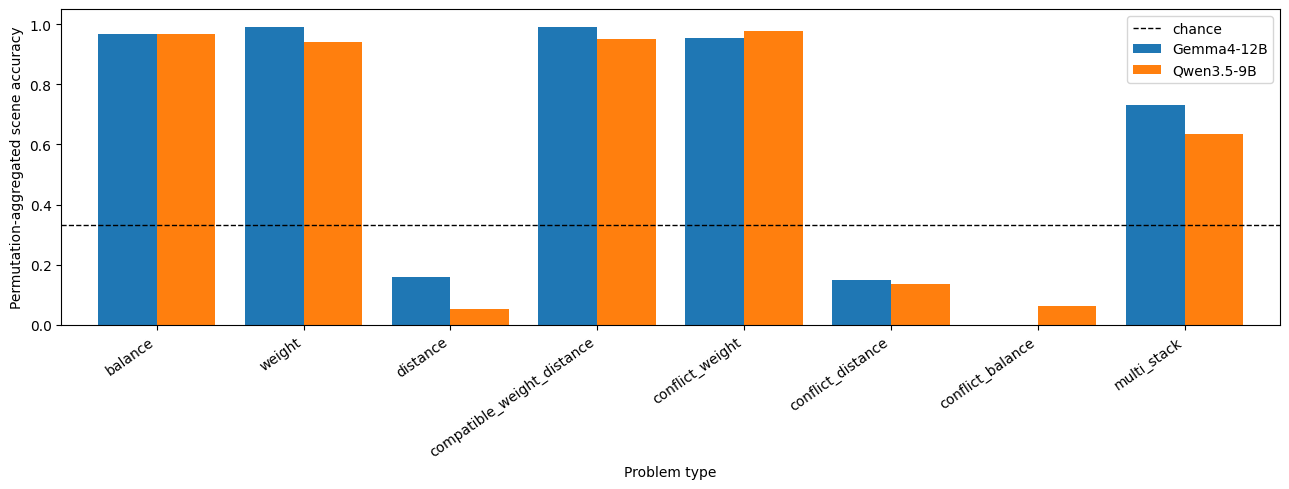

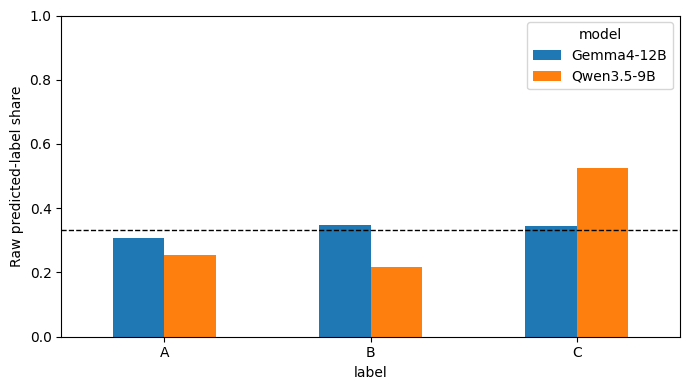

In [7]:
import matplotlib.pyplot as plt

problem = pd.read_csv(analysis_outputs['problem_type_comparison_csv'])
order = [
    'balance', 'weight', 'distance', 'compatible_weight_distance',
    'conflict_weight', 'conflict_distance', 'conflict_balance', 'multi_stack',
]
pivot = problem.pivot(index='problem_type', columns='model', values='aggregated_accuracy').reindex(order)
ax = pivot.plot(kind='bar', figsize=(13, 5), width=0.8)
ax.axhline(1 / 3, color='black', linestyle='--', linewidth=1, label='chance')
ax.set_ylabel('Permutation-aggregated scene accuracy')
ax.set_xlabel('Problem type')
ax.set_ylim(0, 1.05)
ax.legend()
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

label_rows = []
for model, report in summary.items():
    for label, share in report['raw_predicted_label_shares'].items():
        label_rows.append({'model': model, 'label': label, 'share': share})
label_frame = pd.DataFrame(label_rows).pivot(index='label', columns='model', values='share')
ax = label_frame.plot(kind='bar', figsize=(7, 4))
ax.axhline(1 / 3, color='black', linestyle='--', linewidth=1)
ax.set_ylabel('Raw predicted-label share')
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Perception-versus-computation diagnostics


,model,question_kind,pair_count,scene_count,image_accuracy,symbolic_accuracy,symbolic_minus_image_accuracy,symbolic_minus_image_scene_bootstrap_95_ci,semantic_agreement_rate
0,Gemma4-12B,left_distance,96,96,0.2917,1.0000,0.7083,"[0.6145833333333334, 0.8020833333333334]",0.2917
1,Gemma4-12B,left_units,120,120,0.7583,0.9333,0.1750,"[0.1, 0.25]",0.7750
2,Gemma4-12B,outcome,720,120,0.6208,0.8153,0.1944,"[0.1125, 0.2777777777777778]",0.6292
3,Gemma4-12B,right_distance,96,96,0.6250,1.0000,0.3750,"[0.28125, 0.4791666666666667]",0.6250
4,Gemma4-12B,right_units,120,120,0.6833,0.9333,0.2500,"[0.1664583333333334, 0.3333333333333333]",0.6750
5,Qwen3.5-9B,left_distance,96,96,0.4479,1.0000,0.5521,"[0.4479166666666667, 0.6458333333333334]",0.4479
6,Qwen3.5-9B,left_units,120,120,0.8417,0.9333,0.0917,"[0.03333333333333333, 0.15]",0.8833
7,Qwen3.5-9B,outcome,720,120,0.5528,0.6167,0.0639,"[-0.020833333333333325, 0.1500347222222217]",0.5903
8,Qwen3.5-9B,right_distance,96,96,0.5208,1.0000,0.4792,"[0.375, 0.5731770833333295]",0.5208
9,Qwen3.5-9B,right_units,120,120,0.8417,0.8750,0.0333,"[-0.025, 0.09166666666666666]",0.8417


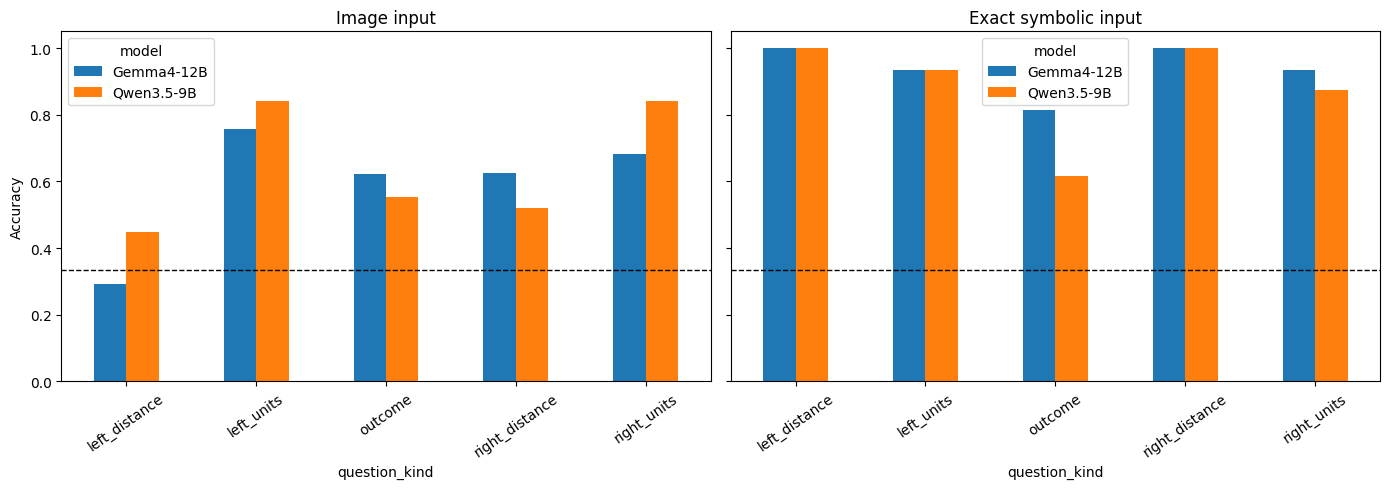

In [8]:
diagnostics = read_json(analysis_outputs['perception_computation_diagnostics'])
control = pd.read_csv(analysis_outputs['control_by_question_kind_csv'])
display(control.round(4))

if not control.empty:
    image = control.pivot(index='question_kind', columns='model', values='image_accuracy')
    symbolic = control.pivot(index='question_kind', columns='model', values='symbolic_accuracy')
    figure, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    image.plot(kind='bar', ax=axes[0], title='Image input')
    symbolic.plot(kind='bar', ax=axes[1], title='Exact symbolic input')
    for axis in axes:
        axis.axhline(1 / 3, color='black', linestyle='--', linewidth=1)
        axis.set_ylim(0, 1.05)
        axis.set_ylabel('Accuracy')
        axis.tick_params(axis='x', rotation=35)
    plt.tight_layout()
    plt.show()

for model, report in diagnostics.items():
    if 'full_outcome' not in report:
        print(f'{model}: full symbolic outcome is still missing; run section 11 of the behavior notebook.')

## Freeze the activation discovery set

The manifest intentionally contains only `probe_train` and `probe_dev`.


In [9]:
activation = pd.read_json(analysis_outputs['activation_pilot_manifest'], lines=True)
assert set(activation['split']) <= {'probe_train', 'probe_dev'}
print('Activation discovery scenes:', len(activation))
display(pd.crosstab(activation['analysis_stratum'], activation['split']))
display(pd.crosstab(activation['analysis_stratum'], activation['cross_model_pattern']))
print('Frozen manifest:', analysis_outputs['activation_pilot_manifest'])

Activation discovery scenes: 254


split,probe_dev,probe_train
analysis_stratum,,
balance,2,22
compatible_weight_distance,3,27
conflict_balance,2,18
conflict_distance,3,27
conflict_weight,3,27
distance,0,30
multi_stack__weight_shortcut_agrees,2,28
multi_stack__weight_shortcut_conflicts,3,27
weight,1,29


cross_model_pattern,Gemma4-12B=correct__Qwen3.5-9B=correct,Gemma4-12B=correct__Qwen3.5-9B=wrong,Gemma4-12B=wrong__Qwen3.5-9B=correct,Gemma4-12B=wrong__Qwen3.5-9B=wrong
analysis_stratum,,,,
balance,22,1,1,0
compatible_weight_distance,23,5,2,0
conflict_balance,0,0,0,20
conflict_distance,3,9,8,10
conflict_weight,22,2,6,0
distance,1,12,6,11
multi_stack__weight_shortcut_agrees,9,8,5,8
multi_stack__weight_shortcut_conflicts,8,8,7,7
weight,24,5,1,0


Frozen manifest: /content/drive/MyDrive/VisualTorque/results/behavior_comparison_v2/activation_pilot_manifest.jsonl


## Interpretation discipline
